# Gaussian-process surrogate



## Purpose

Compare a Gaussian-process surrogate with the earlier models on unseen validation geometries and examine its conditional predictive intervals. The GP was selected as the final surrogate before opening the test targets.


In [1]:
from pathlib import Path
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TRAIN_PATH = PROJECT_ROOT / "data" / "prepared" / "train.csv"
VALIDATION_PATH = PROJECT_ROOT / "data" / "prepared" / "validation.csv"
PREDICTIONS_PATH = PROJECT_ROOT / "results" / "predictions.csv"
METRICS_PATH = PROJECT_ROOT / "results" / "validation_metrics.csv"
CV_PATH = PROJECT_ROOT / "results" / "cv_model_selection.csv"
UNCERTAINTY_PATH = PROJECT_ROOT / "results" / "gp_uncertainty_metrics.csv"
MODEL_PATH = PROJECT_ROOT / "results" / "models" / "gaussian_process.joblib"

MODEL_NAME = "gaussian_process"
FEATURE_NAMES = [
    "IB_Flap_Deflection",
    "OB_Flap_Deflection",
    "IB_Flap_Gap_Multiplier",
    "OB_Flap_Gap_Multiplier",
    "IB_Slat_Deflection",
    "OB_Slat_Deflection",
    "IB_Slat_Gap_Multiplier",
    "OB_Slat_Gap_Multiplier",
    "AoA",
]
TARGET_NAMES = ["cl", "cd", "cm"]
COMPARISON_MODELS = ["aoa_only", "linear_ols", "polynomial_ridge", MODEL_NAME]
PREDICTION_COLUMNS = [
    "case_id", "GeoID", "AoA", "split", "model", "target",
    "actual", "predicted", "error", "absolute_error", "squared_error",
]
METRIC_COLUMNS = [
    "model", "target", "scope", "AoA", "n_rows",
    "n_geometries", "MAE", "RMSE", "R2",
]
CV_COLUMNS = ["model", "target", "candidate", "mean_cv_RMSE", "std_cv_RMSE", "selected"]
UNCERTAINTY_COLUMNS = [
    "model", "target", "scope", "AoA", "n_rows",
    "coverage_95", "mean_interval_width_95",
]

KERNEL_CANDIDATES = ["rbf_ard", "matern_1.5_ard", "matern_2.5_ard"]

def make_kernel(candidate):
    constant = ConstantKernel(
        constant_value=1.0, constant_value_bounds=(1e-2, 1e2)
    )
    length_scale_options = {
        "length_scale": np.ones(len(FEATURE_NAMES)),
        "length_scale_bounds": (1e-2, 1e2),
    }
    if candidate == "rbf_ard":
        return constant * RBF(**length_scale_options)
    if candidate == "matern_1.5_ard":
        return constant * Matern(nu=1.5, **length_scale_options)
    if candidate == "matern_2.5_ard":
        return constant * Matern(nu=2.5, **length_scale_options)
    raise ValueError(f"Unknown kernel candidate: {candidate}")

def make_pipeline(candidate, n_restarts_optimizer):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("gaussian_process", GaussianProcessRegressor(
            kernel=make_kernel(candidate), alpha=1e-6, normalize_y=True,
            n_restarts_optimizer=n_restarts_optimizer, random_state=42,
        )),
    ])

def predict_with_std(pipeline, features):
    scaled_features = pipeline.named_steps["scaler"].transform(features)
    return pipeline.named_steps["gaussian_process"].predict(
        scaled_features, return_std=True
    )

## Load prepared data

In [2]:
train = pd.read_csv(TRAIN_PATH)
validation = pd.read_csv(VALIDATION_PATH)
predictions_before = pd.read_csv(PREDICTIONS_PATH)
metrics_before = pd.read_csv(METRICS_PATH)
cv_before = pd.read_csv(CV_PATH)
uncertainty_before = (
    pd.read_csv(UNCERTAINTY_PATH)
    if UNCERTAINTY_PATH.exists()
    else pd.DataFrame(columns=UNCERTAINTY_COLUMNS)
)

required_columns = ["case_id", "GeoID", *FEATURE_NAMES, *TARGET_NAMES]
assert len(train) == 1_260 and len(validation) == 180
assert set(required_columns).issubset(train.columns)
assert set(required_columns).issubset(validation.columns)
assert train[required_columns].notna().all().all()
assert validation[required_columns].notna().all().all()
assert set(train["GeoID"]).isdisjoint(validation["GeoID"])
assert train.groupby("GeoID").size().eq(10).all()
assert validation.groupby("GeoID").size().eq(10).all()
assert list(predictions_before.columns) == PREDICTION_COLUMNS
assert list(metrics_before.columns) == METRIC_COLUMNS
assert list(cv_before.columns) == CV_COLUMNS
assert list(uncertainty_before.columns) == UNCERTAINTY_COLUMNS

previous_predictions_before = predictions_before.loc[
    ~predictions_before["model"].eq(MODEL_NAME)
].reset_index(drop=True)
previous_metrics_before = metrics_before.loc[
    ~metrics_before["model"].eq(MODEL_NAME)
].reset_index(drop=True)
previous_cv_before = cv_before.loc[
    ~cv_before["model"].eq(MODEL_NAME)
].reset_index(drop=True)
previous_uncertainty_before = uncertainty_before.loc[
    ~uncertainty_before["model"].eq(MODEL_NAME)
].reset_index(drop=True)

display(pd.DataFrame({
    "split": ["train", "validation"],
    "rows": [len(train), len(validation)],
    "geometries": [train["GeoID"].nunique(), validation["GeoID"].nunique()],
    "AoA values": [train["AoA"].nunique(), validation["AoA"].nunique()],
}))


,split,rows,geometries,AoA values
0,train,1260,126,10
1,validation,180,18,10



## Model setup

A separate Pipeline for StandardScaler and then GaussianProcessRegressor. The candidates are ConstantKernel multiplied by RBF ARD, Matérn 1.5 ARD, or Matérn 2.5 ARD. Each kernel has one length scale per input. RBF is infinitely smooth; Matérn 1.5 allows rougher responses; Matérn 2.5 is smooth but not infinitely smooth.

### Model equation

For each normalized target, the GP prior is:

$$
f(\mathbf{x})\sim\mathcal{GP}\left(0,k(\mathbf{x},\mathbf{x}')\right)
$$

Here, $\mathbf{x}$ and $\mathbf{x}'$ are standardized nine-input vectors. The ARD distance uses one length scale per input:

$$
r=\sqrt{\sum_{j=1}^{9}\frac{(x_j-x'_j)^2}{\ell_j^2}}
$$

Here, $\ell_j$ is the length scale for input $j$, and $c>0$ below is the ConstantKernel covariance amplitude.

### Kernel equations

RBF ARD:

$$
k_{\mathrm{RBF}}(\mathbf{x},\mathbf{x}')=c\exp\left(-\frac{r^2}{2}\right)
$$

Matérn 1.5 ARD:

$$
k_{1.5}(\mathbf{x},\mathbf{x}')=c(1+\sqrt{3}r)\exp(-\sqrt{3}r)
$$

Matérn 2.5 ARD:

$$
k_{2.5}(\mathbf{x},\mathbf{x}')=c\left(1+\sqrt{5}r+\frac{5r^2}{3}\right)\exp(-\sqrt{5}r)
$$



All candidates keep the original bounds and initial values, `alpha=1e-6`, `normalize_y=True`, and `random_state=42`.  The saved run used Python 3.10.20 and scikit-learn 1.7.2.



## Cross-validation

Five-fold GroupKFold uses training `GeoID` groups, with the same folds for every target and kernel. A fresh scaler and GP are fitted inside each fold. Kernel family is selected by mean held-out RMSE. Continuous kernel parameters are learned by log marginal likelihood inside each fit.

During CV, `n_restarts_optimizer=2`; this means two additional optimizer starts after the initial optimization. CV SD is the population SD across the five fold RMSE values and describes sensitivity to the held-out geometries. It is not predictive uncertainty. The stored outputs below are from the completed 45-fit CV experiment and were retained without rerunning it during notebook cleanup.


In [3]:
X_train = train.loc[:, FEATURE_NAMES]
X_validation = validation.loc[:, FEATURE_NAMES]
groups = train["GeoID"].to_numpy()
grouped_folds = list(GroupKFold(n_splits=5).split(X_train, groups=groups))

fold_checks = []
for fold, (fit_index, held_out_index) in enumerate(grouped_folds, start=1):
    fit_geometries = set(train.iloc[fit_index]["GeoID"])
    held_out_geometries = set(train.iloc[held_out_index]["GeoID"])
    held_out_counts = train.iloc[held_out_index].groupby("GeoID").size()
    fold_checks.append({
        "fold": fold,
        "fit_rows": len(fit_index),
        "held_out_rows": len(held_out_index),
        "geometry_disjoint": fit_geometries.isdisjoint(held_out_geometries),
        "ten_AoAs_together": held_out_counts.eq(10).all(),
    })
fold_checks = pd.DataFrame(fold_checks)

cv_fold_records = []
fit_state_records = []
warning_records = []
cv_start = time.perf_counter()
for target in TARGET_NAMES:
    for candidate in KERNEL_CANDIDATES:
        for fold, (fit_index, held_out_index) in enumerate(grouped_folds, start=1):
            pipeline = make_pipeline(candidate, n_restarts_optimizer=2)
            with warnings.catch_warnings(record=True) as caught_warnings:
                warnings.simplefilter("always", ConvergenceWarning)
                pipeline.fit(X_train.iloc[fit_index], train[target].iloc[fit_index])
            held_out_prediction = pipeline.predict(X_train.iloc[held_out_index])
            cv_fold_records.append({
                "target": target,
                "candidate": candidate,
                "fold": fold,
                "RMSE": root_mean_squared_error(
                    train[target].iloc[held_out_index], held_out_prediction
                ),
            })
            fit_state_records.append({
                "target": target,
                "candidate": candidate,
                "fold": fold,
                "expected_rows": len(fit_index),
                "scaler_rows": int(pipeline.named_steps["scaler"].n_samples_seen_),
                "gp_rows": pipeline.named_steps["gaussian_process"].X_train_.shape[0],
            })
            for warning in caught_warnings:
                warning_records.append({
                    "phase": "CV", "target": target,
                    "candidate": candidate, "fold": fold,
                    "category": warning.category.__name__,
                    "message": str(warning.message),
                })
cv_seconds = time.perf_counter() - cv_start
cv_fold_results = pd.DataFrame(cv_fold_records)
fit_state = pd.DataFrame(fit_state_records)

summary_records = []
selected_candidates = {}
for target in TARGET_NAMES:
    target_means = {}
    for candidate in KERNEL_CANDIDATES:
        fold_rmse = cv_fold_results.loc[
            cv_fold_results["target"].eq(target)
            & cv_fold_results["candidate"].eq(candidate),
            "RMSE",
        ].to_numpy()
        target_means[candidate] = fold_rmse.mean()
        summary_records.append({
            "model": MODEL_NAME, "target": target,
            "candidate": candidate,
            "mean_cv_RMSE": fold_rmse.mean(),
            "std_cv_RMSE": fold_rmse.std(ddof=0),
            "selected": False,
        })
    selected_candidates[target] = min(
        KERNEL_CANDIDATES, key=lambda name: target_means[name]
    )

gp_cv_summary = pd.DataFrame(summary_records, columns=CV_COLUMNS)
for target, candidate in selected_candidates.items():
    gp_cv_summary.loc[
        gp_cv_summary["target"].eq(target)
        & gp_cv_summary["candidate"].eq(candidate),
        "selected",
    ] = True
updated_cv = pd.concat([previous_cv_before, gp_cv_summary], ignore_index=True).loc[:, CV_COLUMNS]
updated_cv.to_csv(CV_PATH, index=False)
saved_cv = pd.read_csv(CV_PATH)
display(gp_cv_summary)
print(f"Grouped cross-validation fitting time: {cv_seconds:.1f} seconds")

assert fold_checks["geometry_disjoint"].all()
assert fold_checks["ten_AoAs_together"].all()
assert len(fit_state) == len(TARGET_NAMES) * len(KERNEL_CANDIDATES) * 5
assert fit_state["scaler_rows"].eq(fit_state["expected_rows"]).all()
assert fit_state["gp_rows"].eq(fit_state["expected_rows"]).all()
assert not saved_cv.duplicated(["model", "target", "candidate"]).any()
for target in TARGET_NAMES:
    selected_rmse = gp_cv_summary.loc[
        gp_cv_summary["target"].eq(target) & gp_cv_summary["selected"],
        "mean_cv_RMSE",
    ].iloc[0]
    assert np.isclose(
        selected_rmse,
        gp_cv_summary.loc[gp_cv_summary["target"].eq(target), "mean_cv_RMSE"].min(),
    )


,model,target,candidate,mean_cv_RMSE,std_cv_RMSE,selected
0,gaussian_process,cl,rbf_ard,0.050882,0.003398,False
1,gaussian_process,cl,matern_1.5_ard,0.036564,0.002960,True
2,gaussian_process,cl,matern_2.5_ard,0.040196,0.002207,False
3,gaussian_process,cd,rbf_ard,0.015391,0.000727,False
4,gaussian_process,cd,matern_1.5_ard,0.010658,0.000805,True
5,gaussian_process,cd,matern_2.5_ard,0.012025,0.000491,False
6,gaussian_process,cm,rbf_ard,0.085769,0.060044,False
7,gaussian_process,cm,matern_1.5_ard,0.041560,0.003689,True
8,gaussian_process,cm,matern_2.5_ard,0.044818,0.004325,False


Grouped cross-validation fitting time: 5436.8 seconds



## Fit the selected configuration

 Matérn 1.5 ARD was selected independently for all three targets.



In [3]:
pipelines = {}
train_predictions = {}
validation_predictions = {}
train_std = {}
validation_std = {}
final_fit_seconds = {}
for target in TARGET_NAMES:
    candidate = selected_candidates[target]
    pipeline = make_pipeline(candidate, n_restarts_optimizer=5)
    fit_start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", ConvergenceWarning)
        pipeline.fit(X_train, train[target])
    final_fit_seconds[target] = time.perf_counter() - fit_start
    for warning in caught_warnings:
        warning_records.append({
            "phase": "final", "target": target,
            "candidate": candidate, "fold": np.nan,
            "category": warning.category.__name__,
            "message": str(warning.message),
        })
    pipelines[target] = pipeline
    train_predictions[target], train_std[target] = predict_with_std(pipeline, X_train)
    validation_predictions[target], validation_std[target] = predict_with_std(
        pipeline, X_validation
    )

model_bundle = {
    "model_name": MODEL_NAME,
    "feature_names": FEATURE_NAMES,
    "target_names": TARGET_NAMES,
    "selected_candidates": selected_candidates,
    "pipelines": pipelines,
}
joblib.dump(model_bundle, MODEL_PATH)

for target in TARGET_NAMES:
    optimized_kernel = pipelines[target].named_steps["gaussian_process"].kernel_
    print(
        f"{target}: selected {selected_candidates[target]}; "
        f"optimized kernel = {optimized_kernel}; "
        f"final fit time = {final_fit_seconds[target]:.1f} seconds"
    )

warning_table = pd.DataFrame(warning_records)
if warning_table.empty:
    print("No fitting warnings were raised.")
else:
    warning_summary = (
        warning_table.groupby(
            ["phase", "target", "candidate", "category", "message"],
            dropna=False, sort=False,
        )
        .size().rename("count").reset_index()
    )
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(warning_summary)
    print(
        "Warnings are shown so boundary-limited kernel parameters are visible. "
        "They indicate an optimizer limit, not a measured uncertainty guarantee."
    )

reloaded_bundle = joblib.load(MODEL_PATH)
for target in TARGET_NAMES:
    reproduced_train, reproduced_train_std = predict_with_std(
        reloaded_bundle["pipelines"][target], X_train
    )
    reproduced_validation, reproduced_validation_std = predict_with_std(
        reloaded_bundle["pipelines"][target], X_validation
    )
    assert np.allclose(reproduced_train, train_predictions[target])
    assert np.allclose(reproduced_train_std, train_std[target])
    assert np.allclose(reproduced_validation, validation_predictions[target])
    assert np.allclose(reproduced_validation_std, validation_std[target])


cl: selected matern_1.5_ard; optimized kernel = 1.25**2 * Matern(length_scale=[11.4, 10.2, 53.8, 99.2, 3.73, 3.82, 33.5, 25.9, 1.39], nu=1.5); final fit time = 157.1 seconds
cd: selected matern_1.5_ard; optimized kernel = 0.66**2 * Matern(length_scale=[8.32, 7.67, 55, 100, 5.48, 2.07, 100, 37.8, 1.24], nu=1.5); final fit time = 132.3 seconds
cm: selected matern_1.5_ard; optimized kernel = 1.09**2 * Matern(length_scale=[7.04, 6.57, 100, 54.6, 1.31, 2.67, 16.5, 31.1, 0.998], nu=1.5); final fit time = 421.6 seconds


,phase,target,candidate,category,message,count
0,CV,cl,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,2
1,CV,cl,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 2 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1
2,CV,cd,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,5
3,CV,cd,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 6 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1
4,CV,cd,matern_2.5_ard,ConvergenceWarning,The optimal value found for dimension 6 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1
5,CV,cd,matern_2.5_ard,ConvergenceWarning,The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1
6,CV,cm,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1
7,CV,cm,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 7 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1
8,CV,cm,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 2 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,3
9,final,cd,matern_1.5_ard,ConvergenceWarning,The optimal value found for dimension 3 of parameter k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.,1


Warnings are shown so boundary-limited kernel parameters are visible. They indicate an optimizer limit, not a measured uncertainty guarantee.



## Validation metrics

Training and validation point predictions use the shared long format. Metrics are calculated from the saved validation rows.


In [4]:
def make_prediction_rows(frame, predicted_by_target, split_name):
    rows = []
    for target in TARGET_NAMES:
        target_rows = frame.loc[:, ["case_id", "GeoID", "AoA"]].copy()
        target_rows["split"] = split_name
        target_rows["model"] = MODEL_NAME
        target_rows["target"] = target
        target_rows["actual"] = frame[target].to_numpy()
        target_rows["predicted"] = predicted_by_target[target]
        target_rows["error"] = target_rows["predicted"] - target_rows["actual"]
        target_rows["absolute_error"] = target_rows["error"].abs()
        target_rows["squared_error"] = target_rows["error"].pow(2)
        rows.append(target_rows.loc[:, PREDICTION_COLUMNS])
    return pd.concat(rows, ignore_index=True)

gp_prediction_rows = pd.concat([
    make_prediction_rows(train, train_predictions, "train"),
    make_prediction_rows(validation, validation_predictions, "validation"),
], ignore_index=True)
updated_predictions = pd.concat(
    [previous_predictions_before, gp_prediction_rows], ignore_index=True
).loc[:, PREDICTION_COLUMNS]
updated_predictions.to_csv(PREDICTIONS_PATH, index=False)
saved_predictions = pd.read_csv(PREDICTIONS_PATH)

def metric_record(rows, target, scope, aoa=np.nan):
    actual = rows["actual"].to_numpy()
    predicted = rows["predicted"].to_numpy()
    return {
        "model": MODEL_NAME,
        "target": target,
        "scope": scope,
        "AoA": aoa,
        "n_rows": len(rows),
        "n_geometries": rows["GeoID"].nunique(),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }

def metrics_from_saved_predictions(saved_model_rows):
    records = []
    for target in TARGET_NAMES:
        target_rows = saved_model_rows.loc[saved_model_rows["target"].eq(target)]
        records.append(metric_record(target_rows, target, "overall"))
        for aoa, aoa_rows in target_rows.groupby("AoA", sort=True):
            records.append(metric_record(aoa_rows, target, "per_aoa", aoa))
    return pd.DataFrame(records, columns=METRIC_COLUMNS)

saved_gp_validation = saved_predictions.loc[
    saved_predictions["model"].eq(MODEL_NAME)
    & saved_predictions["split"].eq("validation")
].copy()
gp_metrics = metrics_from_saved_predictions(saved_gp_validation)
updated_metrics = pd.concat(
    [previous_metrics_before, gp_metrics], ignore_index=True
).loc[:, METRIC_COLUMNS]
updated_metrics.to_csv(METRICS_PATH, index=False)
saved_metrics = pd.read_csv(METRICS_PATH)

display(saved_metrics.loc[
    saved_metrics["model"].eq(MODEL_NAME) & saved_metrics["scope"].eq("overall"),
    ["target", "n_rows", "n_geometries", "MAE", "RMSE", "R2"],
].reset_index(drop=True))

assert not saved_predictions.duplicated(["case_id", "split", "model", "target"]).any()
assert not saved_metrics.duplicated(["model", "target", "scope", "AoA"]).any()
pd.testing.assert_frame_equal(
    saved_metrics.loc[saved_metrics["model"].eq(MODEL_NAME)].sort_values(
        ["target", "scope", "AoA"]
    ).reset_index(drop=True),
    metrics_from_saved_predictions(saved_gp_validation).sort_values(
        ["target", "scope", "AoA"]
    ).reset_index(drop=True),
    check_dtype=False, rtol=1e-12, atol=1e-12,
)


,target,n_rows,n_geometries,MAE,RMSE,R2
0,cl,180,18,0.020616,0.037197,0.987627
1,cd,180,18,0.004977,0.010041,0.994114
2,cm,180,18,0.024907,0.043410,0.957790



### uncertainty  measure

Coverage is the fraction of actual values inside the intervals. Mean width is the average upper bound minus lower bound. Wider intervals can increase coverage while reducing precision. The multiplier 1.96 corresponds to the central 95% of a normal distribution. These are nominal 95% GP prediction intervals, conditional on the fitted model; they are not calibrated bounds or safety guarantees.

In [6]:
validation_uncertainty = {}
for target in TARGET_NAMES:
    target_frame = validation.loc[:, ["case_id", "GeoID", "AoA", target]].copy()
    target_frame = target_frame.rename(columns={target: "actual"})
    target_frame["predicted"] = validation_predictions[target]
    target_frame["predicted_std"] = validation_std[target]
    target_frame["absolute_error"] = (
        target_frame["predicted"] - target_frame["actual"]
    ).abs()
    target_frame["lower_95"] = (
        target_frame["predicted"] - 1.96 * target_frame["predicted_std"]
    )
    target_frame["upper_95"] = (
        target_frame["predicted"] + 1.96 * target_frame["predicted_std"]
    )
    target_frame["covered_95"] = target_frame["actual"].between(
        target_frame["lower_95"], target_frame["upper_95"], inclusive="both"
    )
    target_frame["interval_width_95"] = (
        target_frame["upper_95"] - target_frame["lower_95"]
    )
    validation_uncertainty[target] = target_frame

def uncertainty_record(rows, target, scope, aoa=np.nan):
    return {
        "model": MODEL_NAME,
        "target": target,
        "scope": scope,
        "AoA": aoa,
        "n_rows": len(rows),
        "coverage_95": rows["covered_95"].mean(),
        "mean_interval_width_95": rows["interval_width_95"].mean(),
    }

uncertainty_records = []
for target in TARGET_NAMES:
    target_rows = validation_uncertainty[target]
    uncertainty_records.append(uncertainty_record(target_rows, target, "overall"))
    for aoa, aoa_rows in target_rows.groupby("AoA", sort=True):
        uncertainty_records.append(
            uncertainty_record(aoa_rows, target, "per_aoa", aoa)
        )

gp_uncertainty_metrics = pd.DataFrame(uncertainty_records, columns=UNCERTAINTY_COLUMNS)
uncertainty_frames = [gp_uncertainty_metrics]
if not previous_uncertainty_before.empty:
    uncertainty_frames.insert(0, previous_uncertainty_before)
updated_uncertainty = pd.concat(uncertainty_frames, ignore_index=True).loc[
    :, UNCERTAINTY_COLUMNS
]
updated_uncertainty.to_csv(UNCERTAINTY_PATH, index=False)
saved_uncertainty = pd.read_csv(UNCERTAINTY_PATH)

display(saved_uncertainty.loc[
    saved_uncertainty["model"].eq(MODEL_NAME)
    & saved_uncertainty["scope"].eq("overall")
].reset_index(drop=True))

assert len(saved_uncertainty.loc[saved_uncertainty["model"].eq(MODEL_NAME)]) == 33
assert not saved_uncertainty.duplicated(["model", "target", "scope", "AoA"]).any()


,model,target,scope,AoA,n_rows,coverage_95,mean_interval_width_95
0,gaussian_process,cl,overall,NaN,180,0.900000,0.112045
1,gaussian_process,cd,overall,NaN,180,0.894444,0.030764
2,gaussian_process,cm,overall,NaN,180,0.922222,0.133253


## Validation plots

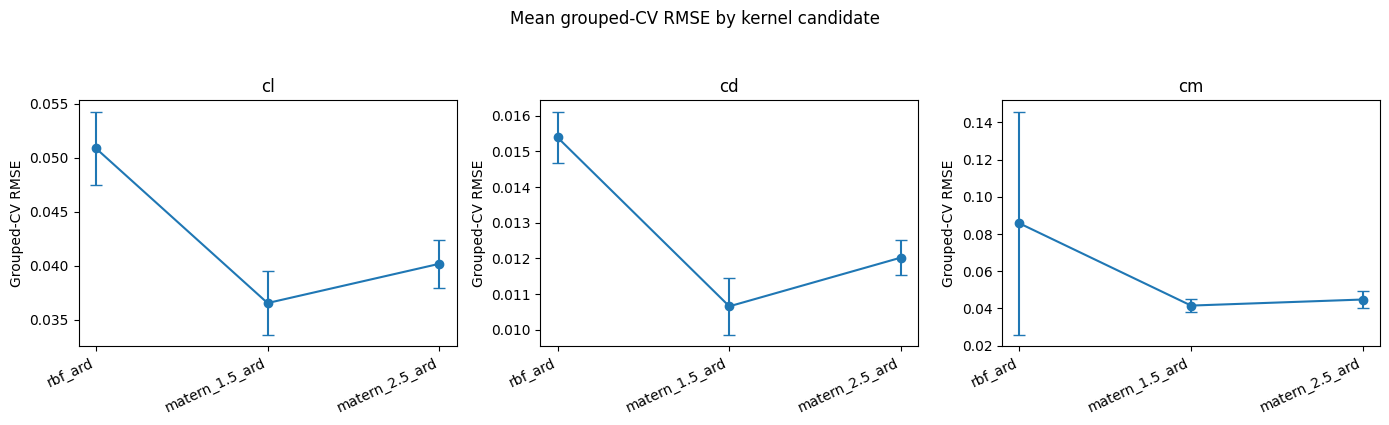

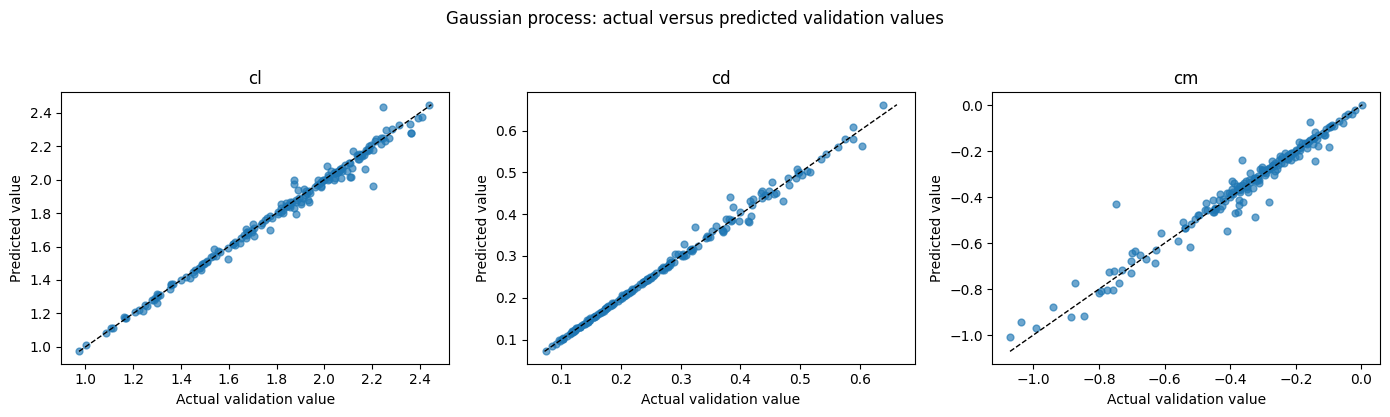

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
candidate_positions = np.arange(len(KERNEL_CANDIDATES))
for axis, target in zip(axes, TARGET_NAMES):
    rows = (
        gp_cv_summary.loc[gp_cv_summary["target"].eq(target)]
        .set_index("candidate").reindex(KERNEL_CANDIDATES)
    )
    axis.errorbar(
        candidate_positions, rows["mean_cv_RMSE"],
        yerr=rows["std_cv_RMSE"], marker="o", capsize=4,
    )
    axis.set_title(target)
    axis.set_xticks(candidate_positions, KERNEL_CANDIDATES, rotation=25, ha="right")
    axis.set_ylabel("Grouped-CV RMSE")
fig.suptitle("Mean grouped-CV RMSE by kernel candidate", y=1.05)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, target in zip(axes, TARGET_NAMES):
    rows = saved_gp_validation.loc[saved_gp_validation["target"].eq(target)]
    axis.scatter(rows["actual"], rows["predicted"], alpha=0.65, s=24)
    limits = [
        min(rows["actual"].min(), rows["predicted"].min()),
        max(rows["actual"].max(), rows["predicted"].max()),
    ]
    axis.plot(limits, limits, color="black", linestyle="--", linewidth=1)
    axis.set_title(target)
    axis.set_xlabel("Actual validation value")
    axis.set_ylabel("Predicted value")
fig.suptitle("Gaussian process: actual versus predicted validation values", y=1.03)
fig.tight_layout()
plt.show()

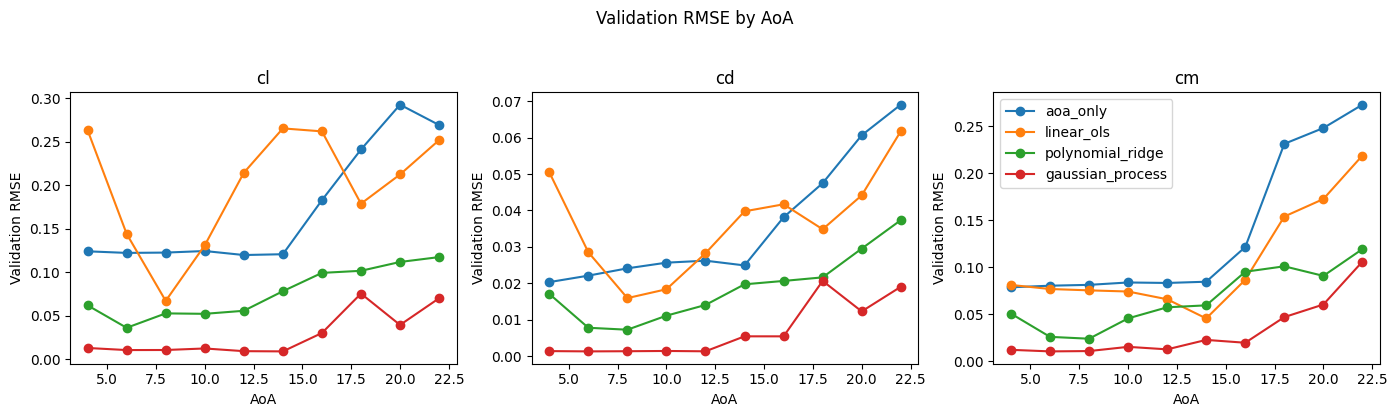

In [8]:
per_aoa_comparison = saved_metrics.loc[
    saved_metrics["model"].isin(COMPARISON_MODELS)
    & saved_metrics["scope"].eq("per_aoa")
].copy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for axis, target in zip(axes, TARGET_NAMES):
    for model_name in COMPARISON_MODELS:
        rows = per_aoa_comparison.loc[
            per_aoa_comparison["target"].eq(target)
            & per_aoa_comparison["model"].eq(model_name)
        ].sort_values("AoA")
        axis.plot(rows["AoA"], rows["RMSE"], marker="o", label=model_name)
    axis.set_title(target)
    axis.set_xlabel("AoA")
    axis.set_ylabel("Validation RMSE")
axes[-1].legend()
fig.suptitle("Validation RMSE by AoA", y=1.03)
fig.tight_layout()
plt.show()

In [ ]:
plot_bundle = joblib.load(MODEL_PATH)
plot_validation = pd.read_csv(VALIDATION_PATH, dtype={"GeoID": "string"})
plot_saved_predictions = pd.read_csv(
    PREDICTIONS_PATH, dtype={"GeoID": "string"}, float_precision="round_trip"
)
plot_saved_uncertainty = pd.read_csv(
    UNCERTAINTY_PATH, float_precision="round_trip"
)
plot_uncertainty = {}

for target in TARGET_NAMES:
    saved_rows = plot_saved_predictions.loc[
        plot_saved_predictions["model"].eq(MODEL_NAME)
        & plot_saved_predictions["split"].eq("validation")
        & plot_saved_predictions["target"].eq(target),
        ["case_id", "GeoID", "AoA", "actual", "predicted"],
    ]
    rows = plot_validation.loc[
        :, [
            "case_id", "GeoID", *plot_bundle["feature_names"]
        ]
    ].merge(
        saved_rows,
        on=["case_id", "GeoID", "AoA"],
        how="left",
        validate="one_to_one",
    )
    pipeline = plot_bundle["pipelines"][target]
    features = rows.loc[:, plot_bundle["feature_names"]]
    scaled_features = pipeline.named_steps["scaler"].transform(features)
    predicted, predicted_std = pipeline.named_steps["gaussian_process"].predict(
        scaled_features, return_std=True
    )
    assert np.allclose(predicted, rows["predicted"])

    rows["predicted_std"] = predicted_std
    rows["lower_95"] = rows["predicted"] - 1.96 * rows["predicted_std"]
    rows["upper_95"] = rows["predicted"] + 1.96 * rows["predicted_std"]
    rows["covered_95"] = rows["actual"].between(
        rows["lower_95"], rows["upper_95"], inclusive="both"
    )
    rows["interval_width_95"] = rows["upper_95"] - rows["lower_95"]
    rows = rows.sort_values(["AoA", "GeoID"], kind="stable").reset_index(drop=True)
    assert len(rows) == 180 and rows["case_id"].is_unique
    plot_uncertainty[target] = rows

    saved_target = plot_saved_uncertainty.loc[
        plot_saved_uncertainty["model"].eq(MODEL_NAME)
        & plot_saved_uncertainty["target"].eq(target)
    ]
    saved_overall = saved_target.loc[saved_target["scope"].eq("overall")].iloc[0]
    assert np.isclose(rows["covered_95"].mean(), saved_overall["coverage_95"])
    assert np.isclose(
        rows["interval_width_95"].mean(),
        saved_overall["mean_interval_width_95"],
    )
    plotted_by_aoa = rows.groupby("AoA").agg(
        coverage_95=("covered_95", "mean"),
        mean_interval_width_95=("interval_width_95", "mean"),
    )
    saved_by_aoa = saved_target.loc[saved_target["scope"].eq("per_aoa")].set_index("AoA")
    assert np.allclose(plotted_by_aoa["coverage_95"], saved_by_aoa["coverage_95"])
    assert np.allclose(
        plotted_by_aoa["mean_interval_width_95"],
        saved_by_aoa["mean_interval_width_95"],
    )


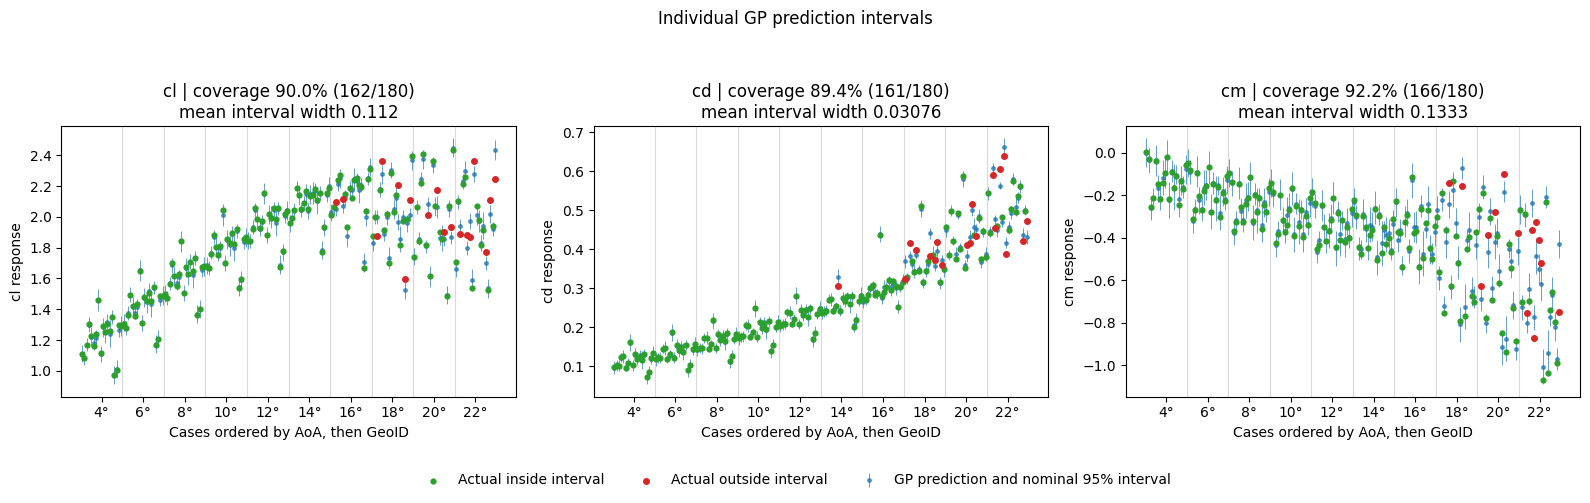

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, target in zip(axes, TARGET_NAMES):
    rows = plot_uncertainty[target]
    positions = np.arange(len(rows))
    covered = rows["covered_95"].to_numpy()
    axis.errorbar(
        positions,
        rows["predicted"],
        yerr=1.96 * rows["predicted_std"],
        fmt="o",
        markersize=2.5,
        color="tab:blue",
        ecolor="tab:blue",
        elinewidth=0.7,
        alpha=0.7,
        capsize=0,
        label="GP prediction and nominal 95% interval",
        zorder=1,
    )
    axis.scatter(
        positions[covered], rows.loc[covered, "actual"],
        s=12, color="tab:green", label="Actual inside interval", zorder=2,
    )
    axis.scatter(
        positions[~covered], rows.loc[~covered, "actual"],
        s=16, color="tab:red", label="Actual outside interval", zorder=3,
    )

    groups = rows.groupby("AoA", sort=True).indices
    centers = [np.mean(indexes) for indexes in groups.values()]
    boundaries = [max(indexes) + 0.5 for indexes in list(groups.values())[:-1]]
    for boundary in boundaries:
        axis.axvline(boundary, color="0.85", linewidth=0.8, zorder=0)
    axis.set_xticks(centers, [f"{aoa:g}°" for aoa in groups])
    axis.set_xlabel("Cases ordered by AoA, then GeoID")
    axis.set_ylabel(f"{target} response")

    covered_count = int(covered.sum())
    total_count = len(rows)
    coverage = covered_count / total_count
    mean_width = rows["interval_width_95"].mean()
    axis.set_title(
        f"{target} | coverage {coverage:.1%} ({covered_count}/{total_count})\n"
        f"mean interval width {mean_width:.4g}"
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.01),
    ncol=3, frameon=False,
)
fig.suptitle("Individual GP prediction intervals", y=0.99)
fig.tight_layout(rect=[0, 0.10, 1, 0.94])
plt.show()


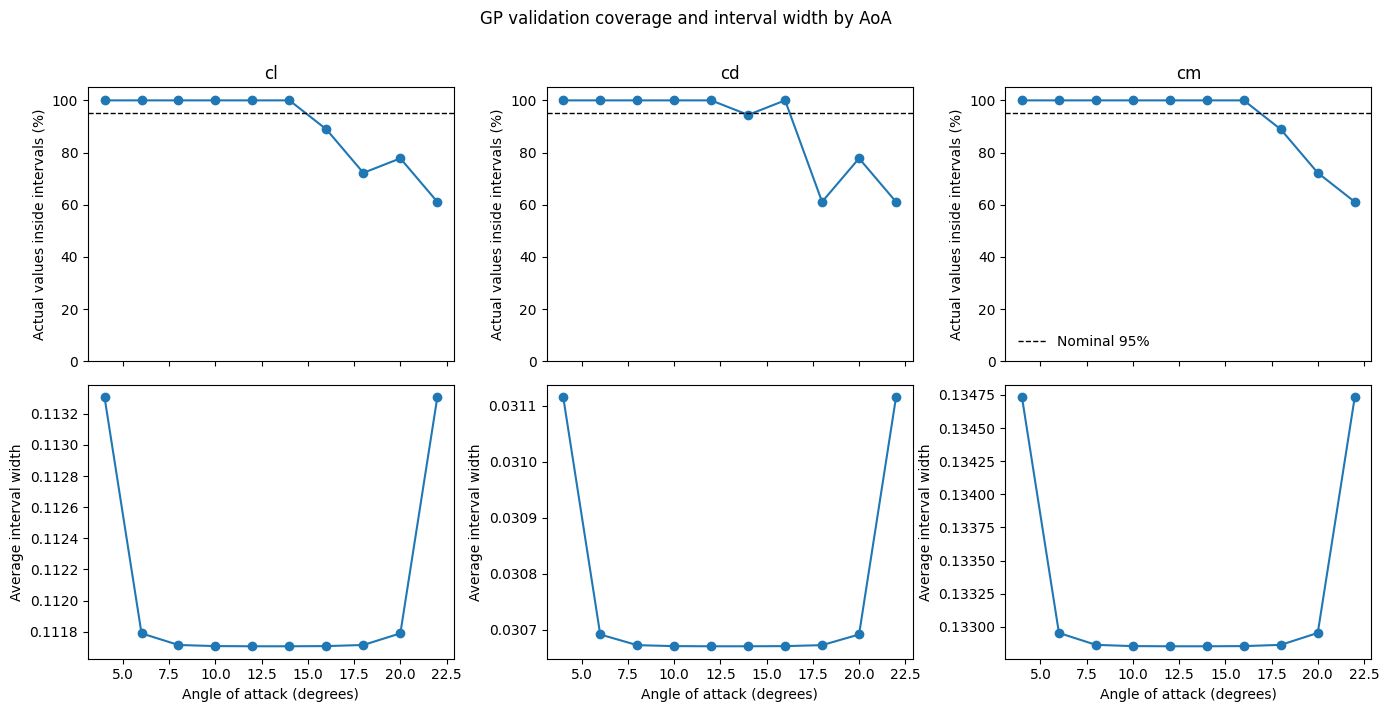

In [4]:
gp_uncertainty_by_aoa = plot_saved_uncertainty.loc[
    plot_saved_uncertainty["model"].eq(MODEL_NAME)
    & plot_saved_uncertainty["scope"].eq("per_aoa")
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex="col")
for column, target in enumerate(TARGET_NAMES):
    rows = gp_uncertainty_by_aoa.loc[
        gp_uncertainty_by_aoa["target"].eq(target)
    ].sort_values("AoA")
    axes[0, column].plot(rows["AoA"], 100 * rows["coverage_95"], marker="o")
    axes[0, column].axhline(
        95, color="black", linestyle="--", linewidth=1, label="Nominal 95%"
    )
    axes[0, column].set_ylim(0, 105)
    axes[0, column].set_title(target)
    axes[0, column].set_ylabel("Actual values inside intervals (%)")
    axes[1, column].plot(
        rows["AoA"], rows["mean_interval_width_95"], marker="o"
    )
    axes[1, column].set_xlabel("Angle of attack (degrees)")
    axes[1, column].set_ylabel("Average interval width")
axes[0, -1].legend(frameon=False)
fig.suptitle("GP validation coverage and interval width by AoA", y=1.01)
fig.tight_layout()
plt.show()


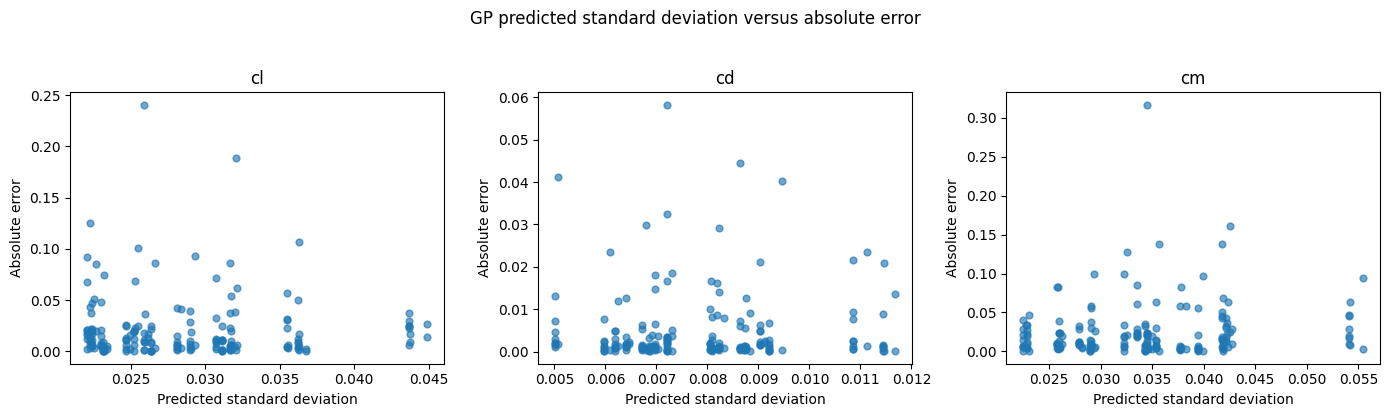

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, target in zip(axes, TARGET_NAMES):
    rows = validation_uncertainty[target]
    axis.scatter(rows["predicted_std"], rows["absolute_error"], alpha=0.65, s=24)
    axis.set_title(target)
    axis.set_xlabel("Predicted standard deviation")
    axis.set_ylabel("Absolute error")
fig.suptitle("GP predicted standard deviation versus absolute error", y=1.03)
fig.tight_layout()
plt.show()


## Model comparison

The table below compares overall validation point-prediction metrics for all four models. Lower MAE and RMSE are better; higher R² is better.


In [5]:
comparison = (
    saved_metrics.loc[
        saved_metrics["model"].isin(COMPARISON_MODELS)
        & saved_metrics["scope"].eq("overall"),
        ["target", "model", "MAE", "RMSE", "R2"],
    ]
    .assign(
        target=lambda frame: pd.Categorical(frame["target"], TARGET_NAMES, ordered=True),
        model=lambda frame: pd.Categorical(
            frame["model"], COMPARISON_MODELS, ordered=True
        ),
    )
    .sort_values(["target", "model"])
)
display(comparison.reset_index(drop=True))

,target,model,MAE,RMSE,R2
0,cl,aoa_only,0.142320,0.184291,0.696275
1,cl,linear_ols,0.178400,0.209156,0.608787
2,cl,polynomial_ridge,0.063269,0.081532,0.940554
3,cl,gaussian_process,0.020616,0.037197,0.987627
4,cd,aoa_only,0.029068,0.039513,0.908863
5,cd,linear_ols,0.031666,0.038803,0.912110
6,cd,polynomial_ridge,0.015438,0.020679,0.975039
7,cd,gaussian_process,0.004977,0.010041,0.994114
8,cm,aoa_only,0.117285,0.156525,0.451207
9,cm,linear_ols,0.086190,0.118004,0.688085



## Short conclusion

The GP improves validation MAE, RMSE, and R² over polynomial Ridge for `cl`, `cd`, and `cm`, although exact GP fitting is much more expensive. 

Based on the saved training-only grouped-CV and validation evidence, the existing Gaussian process is selected as the final surrogate for all three targets before test evaluation. Polynomial Ridge remains the comparison model.



## Save results

The completed experiment wrote `results/predictions.csv`, `results/validation_metrics.csv`, `results/cv_model_selection.csv`, `results/gp_uncertainty_metrics.csv`, and `results/models/gaussian_process.joblib`. Cleanup retained these development results and did not run fitting or optimization.
